In [1]:
# ===================== CELL 1: Setup, Drive, seeds, data config =====================
!pip install -q mne

import os, shutil, zipfile, random, json, time, math, pickle
import numpy as np
import mne
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from google.colab import drive

# ---------- Seeds (from Prototype 6) ----------
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------- Drive mount (stuck-mount fix from 4_HG / 5_HG) ----------
if os.path.isdir('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')
drive.mount('/content/drive')

# ---------- Paths ----------
OLD_ARTIFACT_DIR = '/content/drive/MyDrive/capstone_artifacts'       # notebook-1 outputs (never overwritten)
DATA_DIR_DRIVE   = os.path.join(OLD_ARTIFACT_DIR, 'processed_data')  # cached encoded windows
NB4_DIR   = os.path.join(OLD_ARTIFACT_DIR, 'nb4_final')              # everything this notebook writes
MODEL_DIR = os.path.join(NB4_DIR, 'models')
OUT_DIR   = os.path.join(NB4_DIR, 'hypergraph')
for p in (DATA_DIR_DRIVE, MODEL_DIR, OUT_DIR):
    os.makedirs(p, exist_ok=True)

# ---------- Raw data (from Prototype 6) ----------
zip_path = '/content/drive/MyDrive/data.zip'
extract_path = '/content/chb01_data'
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_path)
data_dir = os.path.join(extract_path, 'data')

# ---------- Hardware ----------
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- Data / encoding config (from Prototype 6) ----------
TARGET_CHANNELS = ['F7-T7', 'T7-P7', 'F8-T8', 'T8-P8-0']
N_LEVELS = 16
N_CORE_LEVELS = 12
WINDOW_SAMPLES = 2048   # 8 s @ 256 Hz
SFREQ = 256

REFERENCE_FILE = 'chb01_03.edf'
REFERENCE_TMIN, REFERENCE_TMAX = 0, 300

SEIZURE_TIMES = {
    'chb01_16.edf': [(1015, 1066)],
    'chb01_03.edf': [(2996, 3036)],
    'chb01_04.edf': [(1467, 1494)],
    'chb01_15.edf': [(1732, 1772)],
    'chb01_18.edf': [(1720, 1810)],
    'chb01_21.edf': [(327, 420)],
    'chb01_26.edf': [(1862, 1963)],
}

TRAIN_FILES = ['chb01_03.edf', 'chb01_04.edf', 'chb01_15.edf', 'chb01_21.edf', 'chb01_26.edf']
VAL_FILES   = ['chb01_16.edf']
TEST_FILES  = ['chb01_18.edf']      # NEW: held-out test file (4_HG evaluates on a test set)

# ---------- Checks ----------
print(f"Torch {torch.__version__} | device: {device}" +
      (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else "") + f" | seed: {SEED}")

edfs = sorted(f for f in os.listdir(data_dir) if f.endswith('.edf')) if os.path.isdir(data_dir) else []
print(f"\nEDF files found in {data_dir}: {len(edfs)}")
print("  " + ", ".join(edfs) if edfs else "  (none: check the data.zip folder structure)")

print("\nRequired files:")
for f in sorted(set(TRAIN_FILES + VAL_FILES + TEST_FILES + [REFERENCE_FILE])):
    print(f"  {'✅' if f in edfs else '❌'} {f}")

print("\nCached encoded windows in Drive:")
for f in ['train_windows.npy', 'train_labels.npy', 'val_windows.npy', 'val_labels.npy']:
    p = os.path.join(DATA_DIR_DRIVE, f)
    ok = os.path.exists(p)
    print(f"  {'✅' if ok else '❌'} {f:<20}" + (f"{os.path.getsize(p)/1e6:>10.1f} MB" if ok else ""))

print(f"\nThis notebook writes to: {NB4_DIR}")
print("Cell 1 complete. Config locked.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 130.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Mounted at /content/drive
Torch 2.11.0+cu130 | device: cuda (NVIDIA L4) | seed: 42

EDF files found in /content/chb01_data/data: 9
  chb01_01.edf, chb01_03.edf, chb01_04.edf, chb01_05.edf, chb01_15.edf, chb01_16.edf, chb01_18.edf, chb01_21.edf, chb01_26.edf

Required files:
  ✅ chb01_03.edf
  ✅ chb01_04.edf
  ✅ chb01_15.edf
  ✅ chb01_16.edf
  ✅ chb01_18.edf
  ✅ chb01_21.edf
  ✅ chb01_26.edf

Cached encoded windows in Drive:
  ✅ train_windows.npy        273.9 MB
  ✅ train_labels.npy           0.0 MB
  ✅ val_windows.npy           59.0 MB
  ✅ val_labels.npy             0.0 MB

This not

/tmp/ipykernel_766/4144133655.py:15: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


Reference step sizes (uV): [34.51 33.24 32.56 28.07]
  identical to Prototype 6 encoding: True
Processing chb01_18.edf...


/tmp/ipykernel_766/4144133655.py:15: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(path, preload=True, verbose=False)


  -> 450 windows, 11 seizure-labeled

Encoded and cached test windows.

split    windows                 shape  seizure      %
train       2090      (2090, 64, 2048)       40   1.9%
val          450       (450, 64, 2048)        6   1.3%
test         450       (450, 64, 2048)       11   2.4%


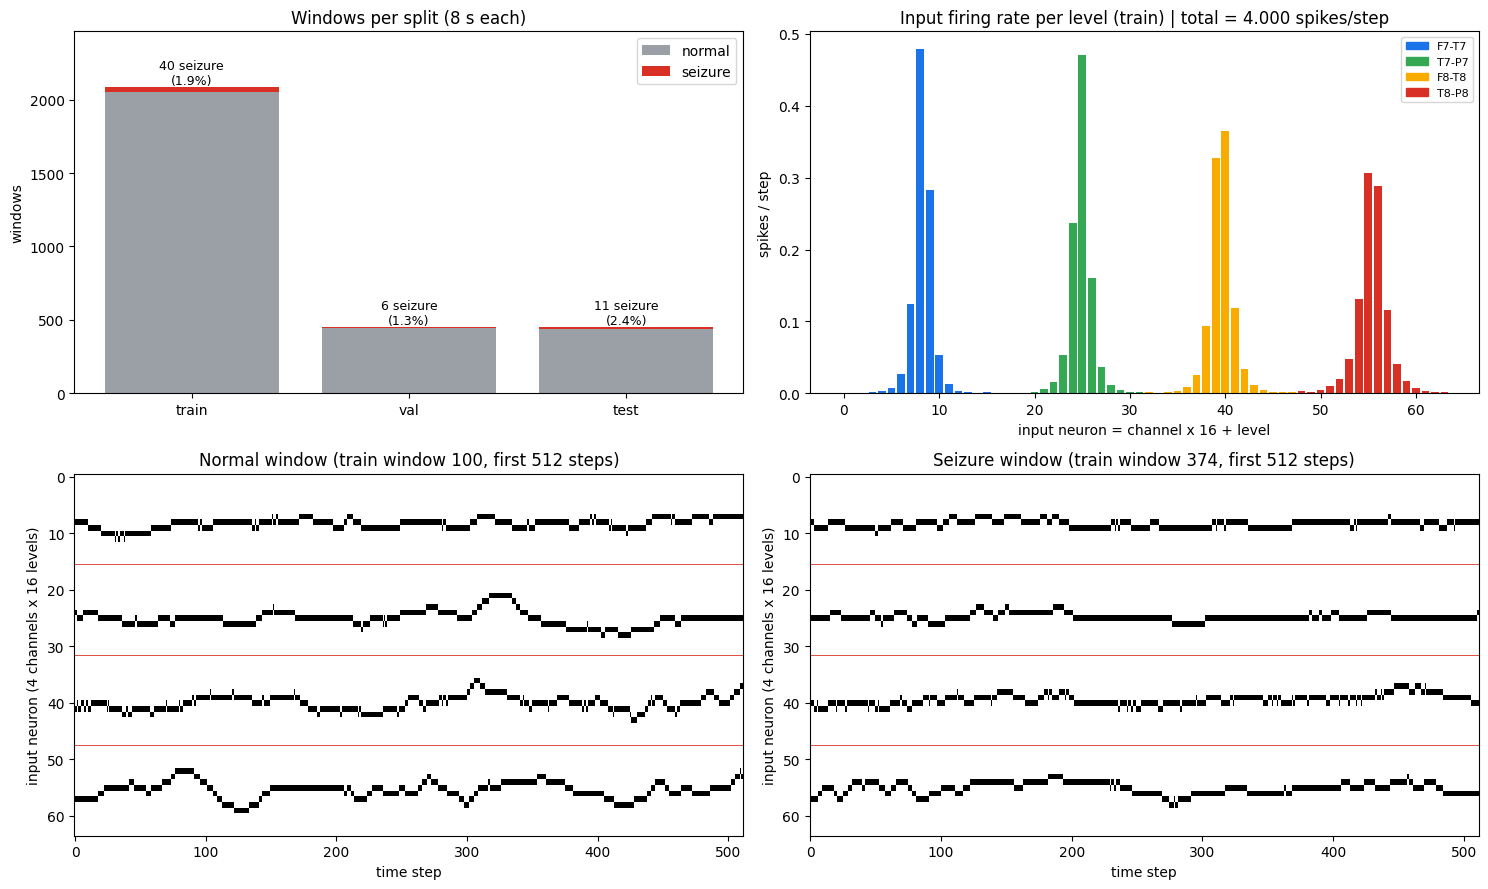


GPU tensors ready: train (2090, 64, 2048), val (450, 64, 2048), test (450, 64, 2048)
Saved figure: /content/drive/MyDrive/Prototype_7/figures/01_data_overview.png
Cell 2 complete.


In [2]:
# ===================== CELL 2: Data (encode test file, GPU tensors) + overview graphs =====================

# ---------- Save location: everything from this notebook lives in "Prototype_7" ----------
PROTO7_DIR = '/content/drive/MyDrive/Prototype_7'
MODEL_DIR  = os.path.join(PROTO7_DIR, 'models')
OUT_DIR    = os.path.join(PROTO7_DIR, 'hypergraph')
FIG_DIR    = os.path.join(PROTO7_DIR, 'figures')
DATA_NEW   = os.path.join(PROTO7_DIR, 'processed_data')
for p in (MODEL_DIR, OUT_DIR, FIG_DIR, DATA_NEW):
    os.makedirs(p, exist_ok=True)

# ---------- Encoding functions (copied from Prototype 6, Cell 2) ----------
def load_raw(filename, channels=TARGET_CHANNELS):
    path = os.path.join(data_dir, filename)
    raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
    return raw.copy().pick(channels)

def compute_reference_stats(ref_data_uv, n_core_levels=N_CORE_LEVELS):
    ch_min = ref_data_uv.min(axis=1)
    ch_max = ref_data_uv.max(axis=1)
    step = (ch_max - ch_min) / n_core_levels
    return ch_min, ch_max, step

def amplitude_to_level(voltage, ch_min, ch_max, step, n_levels=N_LEVELS):
    start = ch_min - 2 * step
    edges = start + step * np.arange(n_levels + 1)
    level = np.digitize(voltage, edges) - 1
    level = np.clip(level, 0, n_levels - 1)
    return level

def encode_to_spikes(data_uv, ch_min, ch_max, step, n_levels=N_LEVELS):
    n_channels, n_samples = data_uv.shape
    spike_matrix = np.zeros((n_channels * n_levels, n_samples), dtype=np.uint8)
    for ch_i in range(n_channels):
        levels = amplitude_to_level(data_uv[ch_i], ch_min[ch_i], ch_max[ch_i], step[ch_i], n_levels)
        for t in range(n_samples):
            row = ch_i * n_levels + levels[t]
            spike_matrix[row, t] = 1
    return spike_matrix

def make_windows(spike_matrix, sfreq, seizure_intervals, window_size=WINDOW_SAMPLES, label_threshold=0.5):
    n_rows, n_samples = spike_matrix.shape
    windows, labels = [], []
    for start in range(0, n_samples - window_size + 1, window_size):
        end = start + window_size
        window = spike_matrix[:, start:end]
        overlap = 0
        for (sz_start, sz_end) in seizure_intervals:
            sz_start_sample = sz_start * sfreq
            sz_end_sample = sz_end * sfreq
            overlap += max(0, min(end, sz_end_sample) - max(start, sz_start_sample))
        fraction = overlap / window_size
        label = 1.0 if fraction >= label_threshold else 0.0
        windows.append(window)
        labels.append(label)
    return np.array(windows), np.array(labels)

def process_record(filename, ch_min, ch_max, step):
    print(f"Processing {filename}...")
    raw = load_raw(filename)
    data_uv = raw.get_data() * 1e6
    spike_matrix = encode_to_spikes(data_uv, ch_min, ch_max, step)
    seizure_intervals = SEIZURE_TIMES.get(filename, [])
    windows, labels = make_windows(spike_matrix, SFREQ, seizure_intervals)
    print(f"  -> {windows.shape[0]} windows, {int(labels.sum())} seizure-labeled")
    return windows, labels

# ---------- Reference stats (so the test file is encoded exactly like train/val) ----------
raw_ref = load_raw(REFERENCE_FILE)
ref_data_uv = raw_ref.get_data(tmin=REFERENCE_TMIN, tmax=REFERENCE_TMAX) * 1e6
ch_min, ch_max, step = compute_reference_stats(ref_data_uv)
expected_step = np.array([34.51, 33.24, 32.56, 28.07])        # printed by Prototype 6
print("Reference step sizes (uV):", np.round(step, 2))
print("  identical to Prototype 6 encoding:", bool(np.allclose(step, expected_step, atol=0.05)))

# ---------- Train / val: reuse the cached windows from Prototype 6 ----------
train_windows = np.load(os.path.join(DATA_DIR_DRIVE, 'train_windows.npy'))
train_labels  = np.load(os.path.join(DATA_DIR_DRIVE, 'train_labels.npy'))
val_windows   = np.load(os.path.join(DATA_DIR_DRIVE, 'val_windows.npy'))
val_labels    = np.load(os.path.join(DATA_DIR_DRIVE, 'val_labels.npy'))

# ---------- Test: encode chb01_18 once, then cache in Prototype_7 ----------
tw_path = os.path.join(DATA_NEW, 'test_windows.npy')
tl_path = os.path.join(DATA_NEW, 'test_labels.npy')
if os.path.exists(tw_path) and os.path.exists(tl_path):
    test_windows, test_labels = np.load(tw_path), np.load(tl_path)
    print("\nLoaded cached test windows.")
else:
    tw_list, tl_list = [], []
    for f in TEST_FILES:
        w, l = process_record(f, ch_min, ch_max, step)
        tw_list.append(w); tl_list.append(l)
    test_windows = np.concatenate(tw_list, axis=0)
    test_labels  = np.concatenate(tl_list, axis=0)
    np.save(tw_path, test_windows); np.save(tl_path, test_labels)
    print("\nEncoded and cached test windows.")

# ---------- Sanity checks ----------
splits_w = {'train': train_windows, 'val': val_windows, 'test': test_windows}
splits_l = {'train': train_labels,  'val': val_labels,  'test': test_labels}
print(f"\n{'split':<7}{'windows':>9}{'shape':>22}{'seizure':>9}{'%':>7}")
for k in splits_w:
    w, l = splits_w[k], splits_l[k]
    assert w.shape[1:] == (64, WINDOW_SAMPLES), f"{k}: unexpected shape {w.shape}"
    assert (w[:5].sum(axis=1) == 4).all(), f"{k}: input is not one-hot (4 spikes per step expected)"
    print(f"{k:<7}{len(l):>9}{str(w.shape):>22}{int(l.sum()):>9}{100*l.mean():>6.1f}%")

# ---------- GPU tensors (uint8 stays small; converted per batch) ----------
train_x_u8 = torch.from_numpy(train_windows).to(device)
val_x_u8   = torch.from_numpy(val_windows).to(device)
test_x_u8  = torch.from_numpy(test_windows).to(device)
train_y = torch.from_numpy(train_labels).float().to(device)
val_y   = torch.from_numpy(val_labels).float().to(device)
test_y  = torch.from_numpy(test_labels).float().to(device)

def to_bt(x_u8):
    """(B, 64, T) uint8 -> (B, T, 64) float32: the batch-first layout the 4_HG SNN expects."""
    return x_u8.permute(0, 2, 1).float().contiguous()

# ---------- Graphs ----------
ch_names = ['F7-T7', 'T7-P7', 'F8-T8', 'T8-P8']
ch_colors = ['#1a73e8', '#34a853', '#f9ab00', '#d93025']

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 2)

# (a) windows per split
ax = fig.add_subplot(gs[0, 0])
names = list(splits_l)
n_seiz = [int(splits_l[k].sum()) for k in names]
n_norm = [len(splits_l[k]) - s for k, s in zip(names, n_seiz)]
ax.bar(names, n_norm, color='#9aa0a6', label='normal')
ax.bar(names, n_seiz, bottom=n_norm, color='#d93025', label='seizure')
for i, (a, b) in enumerate(zip(n_norm, n_seiz)):
    ax.text(i, a + b, f"{b} seizure\n({100*b/(a+b):.1f}%)", ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, max(a + b for a, b in zip(n_norm, n_seiz)) * 1.18)
ax.set_title('Windows per split (8 s each)'); ax.set_ylabel('windows'); ax.legend()

# (b) mean input firing rate per level (train)
ax = fig.add_subplot(gs[0, 1])
rates_in = (train_x_u8.sum(dim=(0, 2), dtype=torch.float32) / (train_x_u8.shape[0] * WINDOW_SAMPLES)).cpu().numpy()
ax.bar(range(64), rates_in, color=[ch_colors[i // 16] for i in range(64)])
ax.set_title(f'Input firing rate per level (train) | total = {rates_in.sum():.3f} spikes/step')
ax.set_xlabel('input neuron = channel x 16 + level'); ax.set_ylabel('spikes / step')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ch_colors], labels=ch_names, fontsize=8)

# (c, d) example spike rasters: first 512 steps of a normal and a seizure window
i_norm = int(np.where(train_labels == 0)[0][100])
i_seiz = int(np.where(train_labels == 1)[0][0])
for col, (idx, title) in enumerate([(i_norm, 'Normal window'), (i_seiz, 'Seizure window')]):
    ax = fig.add_subplot(gs[1, col])
    ax.imshow(train_windows[idx][:, :512], cmap='Greys', aspect='auto', interpolation='none')
    for b in (16, 32, 48):
        ax.axhline(b - 0.5, color='#d93025', lw=0.6)
    ax.set_title(f'{title} (train window {idx}, first 512 steps)')
    ax.set_xlabel('time step'); ax.set_ylabel('input neuron (4 channels x 16 levels)')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_data_overview.png'), dpi=200, bbox_inches='tight')
plt.show()

print(f"\nGPU tensors ready: train {tuple(train_x_u8.shape)}, val {tuple(val_x_u8.shape)}, test {tuple(test_x_u8.shape)}")
print(f"Saved figure: {os.path.join(FIG_DIR, '01_data_overview.png')}")
print("Cell 2 complete.")

Summary file: /content/chb01_data/data/chb01-summary.txt

file          in code (SEIZURE_TIMES)     in chb01-summary.txt        match
chb01_16.edf  [(1015, 1066)]              [(1015, 1066)]              ✅
chb01_03.edf  [(2996, 3036)]              [(2996, 3036)]              ✅
chb01_04.edf  [(1467, 1494)]              [(1467, 1494)]              ✅
chb01_15.edf  [(1732, 1772)]              [(1732, 1772)]              ✅
chb01_18.edf  [(1720, 1810)]              [(1720, 1810)]              ✅
chb01_21.edf  [(327, 420)]                [(327, 420)]                ✅
chb01_26.edf  [(1862, 1963)]              [(1862, 1963)]              ✅

SEIZURE TIMES vs SUMMARY FILE: ALL MATCH ✅

chb01_03 seizure 2996-3036 s
  windows expected from the summary file: [374, 375, 376, 377, 378, 379]
  windows labelled in cached train data : [374, 375, 376, 377, 378, 379]   -> ✅ same
  first labelled window 374 covers 2992-3000 s; seizure starts at 2996 s,
  so only its 2nd half is seizure. Your earlier raster s

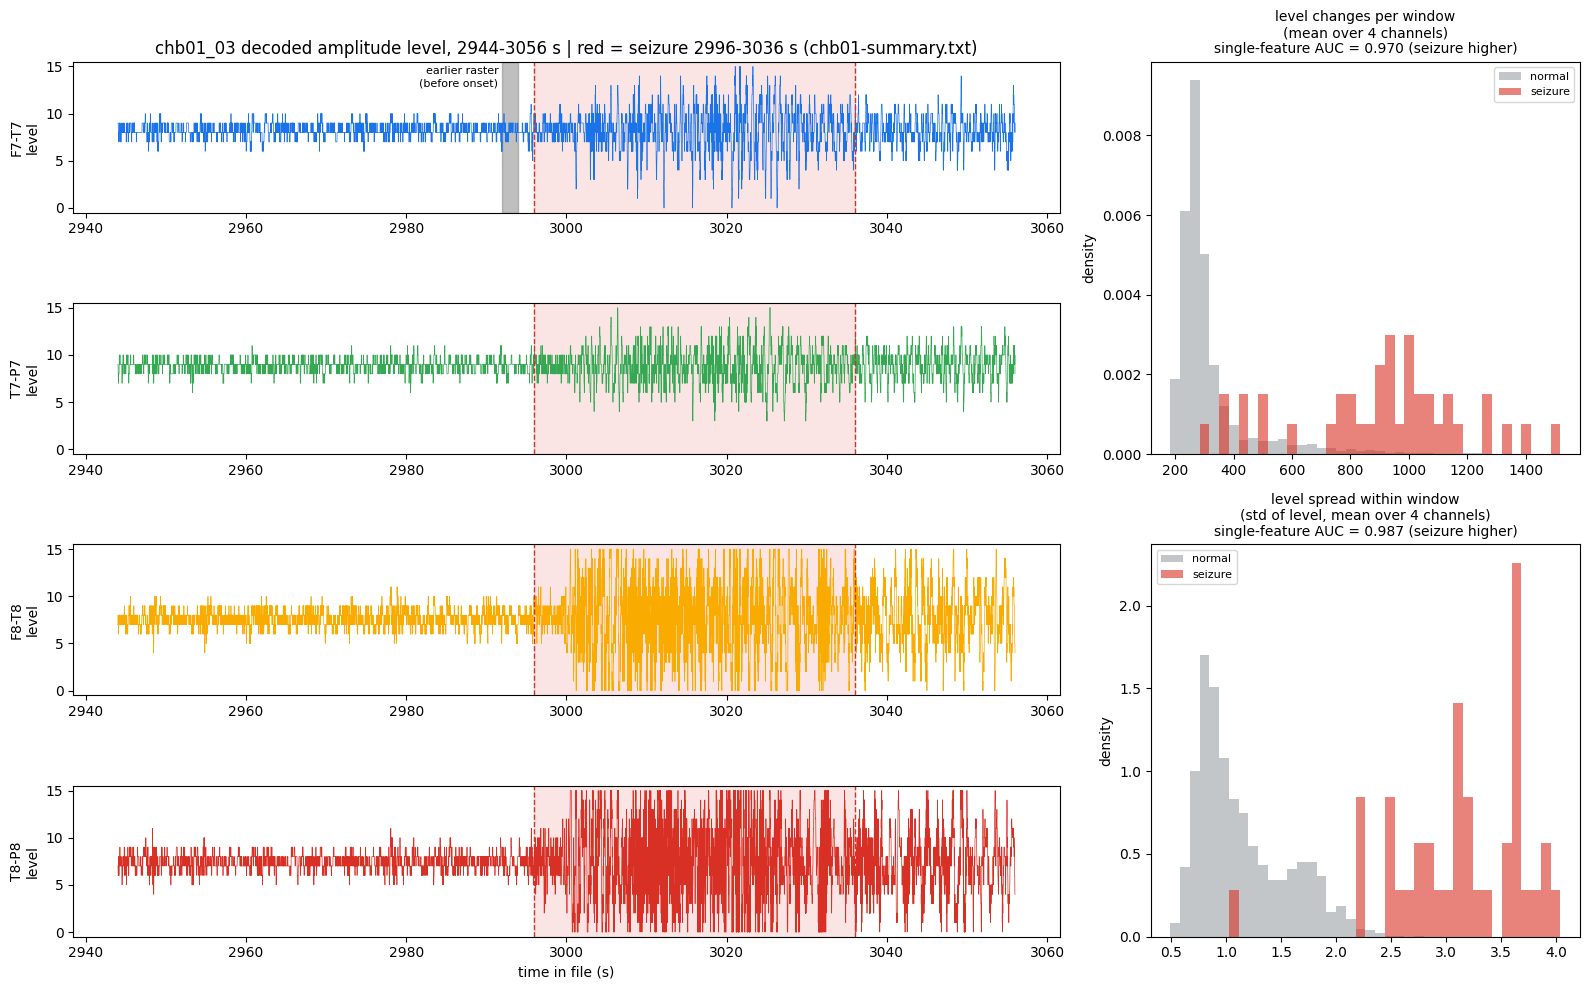


Saved figure: /content/drive/MyDrive/Prototype_7/figures/01b_label_audit_and_seizure_signature.png
Cell 2b complete.


In [3]:
# ===================== CELL 2b: Label audit vs chb01-summary.txt + corrected seizure visualisation =====================
import re

# ---------- 1) Find and parse the official summary file ----------
def parse_summary(path):
    txt = open(path).read()
    out = {}
    for block in txt.split('File Name:')[1:]:
        fname = block.strip().split()[0]
        starts = [int(x) for x in re.findall(r'Seizure\s*\d*\s*Start Time:\s*(\d+)', block)]
        ends   = [int(x) for x in re.findall(r'Seizure\s*\d*\s*End Time:\s*(\d+)', block)]
        out[fname] = list(zip(starts, ends))
    return out

summary_path = os.path.join(data_dir, 'chb01-summary.txt')
if not os.path.exists(summary_path):
    summary_path = None
    for root, _, files in os.walk(extract_path):
        if 'chb01-summary.txt' in files:
            summary_path = os.path.join(root, 'chb01-summary.txt')
            break
print("Summary file:", summary_path)
parsed = parse_summary(summary_path) if summary_path else None

# ---------- 2) Seizure times in code vs summary ----------
if parsed is not None:
    print(f"\n{'file':<14}{'in code (SEIZURE_TIMES)':<28}{'in chb01-summary.txt':<28}match")
    all_ok = True
    for f, iv in SEIZURE_TIMES.items():
        off_iv = parsed.get(f)
        ok = (off_iv is not None) and sorted(off_iv) == sorted(iv)
        all_ok &= ok
        print(f"{f:<14}{str(iv):<28}{str(off_iv):<28}{'✅' if ok else '❌'}")
    print("\nSEIZURE TIMES vs SUMMARY FILE:", "ALL MATCH ✅" if all_ok else "MISMATCH ❌ (tell me which row)")
else:
    print("⚠️ chb01-summary.txt not found: using SEIZURE_TIMES from the code only.")

# ---------- 3) Are the cached chb01_03 windows labelled where the summary says? ----------
ref_iv = (parsed or {}).get('chb01_03.edf', SEIZURE_TIMES['chb01_03.edf'])
on, off = ref_iv[0]

def expected_labeled_windows(intervals, n_windows, win_s=WINDOW_SAMPLES // SFREQ, thr=0.5):
    idx = []
    for k in range(n_windows):
        a, b = k * win_s, (k + 1) * win_s
        ov = sum(max(0, min(b, e) - max(a, s)) for s, e in intervals)
        if ov / win_s >= thr:
            idx.append(k)
    return idx

expected = expected_labeled_windows(ref_iv, 450)                   # chb01_03 = first 450 train windows
actual = np.where(train_labels[:450] == 1)[0].tolist()
print(f"\nchb01_03 seizure {on}-{off} s")
print(f"  windows expected from the summary file: {expected}")
print(f"  windows labelled in cached train data : {actual}   -> {'✅ same' if expected == actual else '❌ DIFFERENT'}")
k = actual[0]
print(f"  first labelled window {k} covers {k*8}-{k*8+8} s; seizure starts at {on} s,")
print(f"  so only its 2nd half is seizure. Your earlier raster showed steps 0-511 = {k*8}-{k*8+2} s (before onset).")

# ---------- 4) Decode one-hot spikes back to a level 0..15 per channel ----------
def decode_levels(w_u8):
    """(N, 64, T) one-hot uint8 -> (N, 4, T) level index (row = channel*16 + level)."""
    n, _, t = w_u8.shape
    return w_u8.reshape(n, 4, N_LEVELS, t).argmax(axis=2).astype(np.int8)

K0, K1 = 368, 382                                                  # windows 368..381 = 2944-3056 s
seg = decode_levels(train_windows[K0:K1]).transpose(1, 0, 2).reshape(4, -1)
t_sec = K0 * 8 + np.arange(seg.shape[1]) / SFREQ

# per-window features over the whole training set
lv_all = np.concatenate([decode_levels(train_windows[i:i + 500]) for i in range(0, len(train_windows), 500)])
feats = {
    'level changes per window\n(mean over 4 channels)': (np.diff(lv_all, axis=2) != 0).sum(axis=2).mean(axis=1),
    'level spread within window\n(std of level, mean over 4 channels)': lv_all.astype(np.float32).std(axis=2).mean(axis=1),
}

# ---------- 5) Figure ----------
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(4, 2, width_ratios=[2.3, 1])
axes = []
for c in range(4):
    ax = fig.add_subplot(gs[c, 0], sharex=axes[0] if axes else None)
    ax.plot(t_sec, seg[c], lw=0.5, color=ch_colors[c])
    ax.axvspan(on, off, color='#d93025', alpha=0.12)
    ax.axvline(on, color='#d93025', ls='--', lw=1)
    ax.axvline(off, color='#d93025', ls='--', lw=1)
    ax.set_ylim(-0.5, 15.5)
    ax.set_ylabel(f'{ch_names[c]}\nlevel')
    axes.append(ax)
axes[0].axvspan(k * 8, k * 8 + 2, color='gray', alpha=0.5)
axes[0].text(k * 8 - 0.5, 15, 'earlier raster\n(before onset)', fontsize=8, va='top', ha='right')
axes[0].set_title(f'chb01_03 decoded amplitude level, 2944-3056 s | red = seizure {on}-{off} s (chb01-summary.txt)')
axes[-1].set_xlabel('time in file (s)')

for r, (title, f) in enumerate(feats.items()):
    ax = fig.add_subplot(gs[2 * r:2 * r + 2, 1])
    bins = np.linspace(f.min(), f.max(), 41)
    ax.hist(f[train_labels == 0], bins=bins, density=True, alpha=0.6, color='#9aa0a6', label='normal')
    ax.hist(f[train_labels == 1], bins=bins, density=True, alpha=0.6, color='#d93025', label='seizure')
    auc = roc_auc_score(train_labels, f)
    direction = 'higher' if auc >= 0.5 else 'lower'
    ax.set_title(f'{title}\nsingle-feature AUC = {max(auc, 1 - auc):.3f} (seizure {direction})', fontsize=10)
    ax.set_ylabel('density'); ax.legend(fontsize=8)
    print(f"\n{title.replace(chr(10), ' ')}: single-feature AUC {max(auc, 1 - auc):.3f} (seizure {direction})")

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, '01b_label_audit_and_seizure_signature.png')
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"\nSaved figure: {fig_path}")
print("Cell 2b complete.")

key       sizes                        nodes  synapses       of  density  cores@32  orphan sources per layer
----------------------------------------------------------------------------------------------------------------
S_dense   [64, 8, 1]                      73       520      520   100.0%         3  [0, 0]
S_sparse  [64, 8, 1]                      73        56      520    10.8%         3  [33, 0]
M_dense   [64, 64, 16, 1]                145      5136     5136   100.0%         5  [0, 0, 0]
M_sparse  [64, 64, 16, 1]                145       496     5136     9.7%         5  [0, 11, 0]
L_dense   [64, 128, 128, 64, 32, 1]      417     34848    34848   100.0%        14  [0, 0, 0, 0, 0]
L_sparse  [64, 128, 128, 64, 32, 1]      417      3488    34848    10.0%        14  [0, 0, 0, 3, 0]
(cores@32 is only for orientation here; the real value is set in the hypergraph cells)

Initial firing (first 64 val windows): per hidden layer = mean rate | silent neurons
  S_dense   H1 0.268 | 0/8
  S_sp

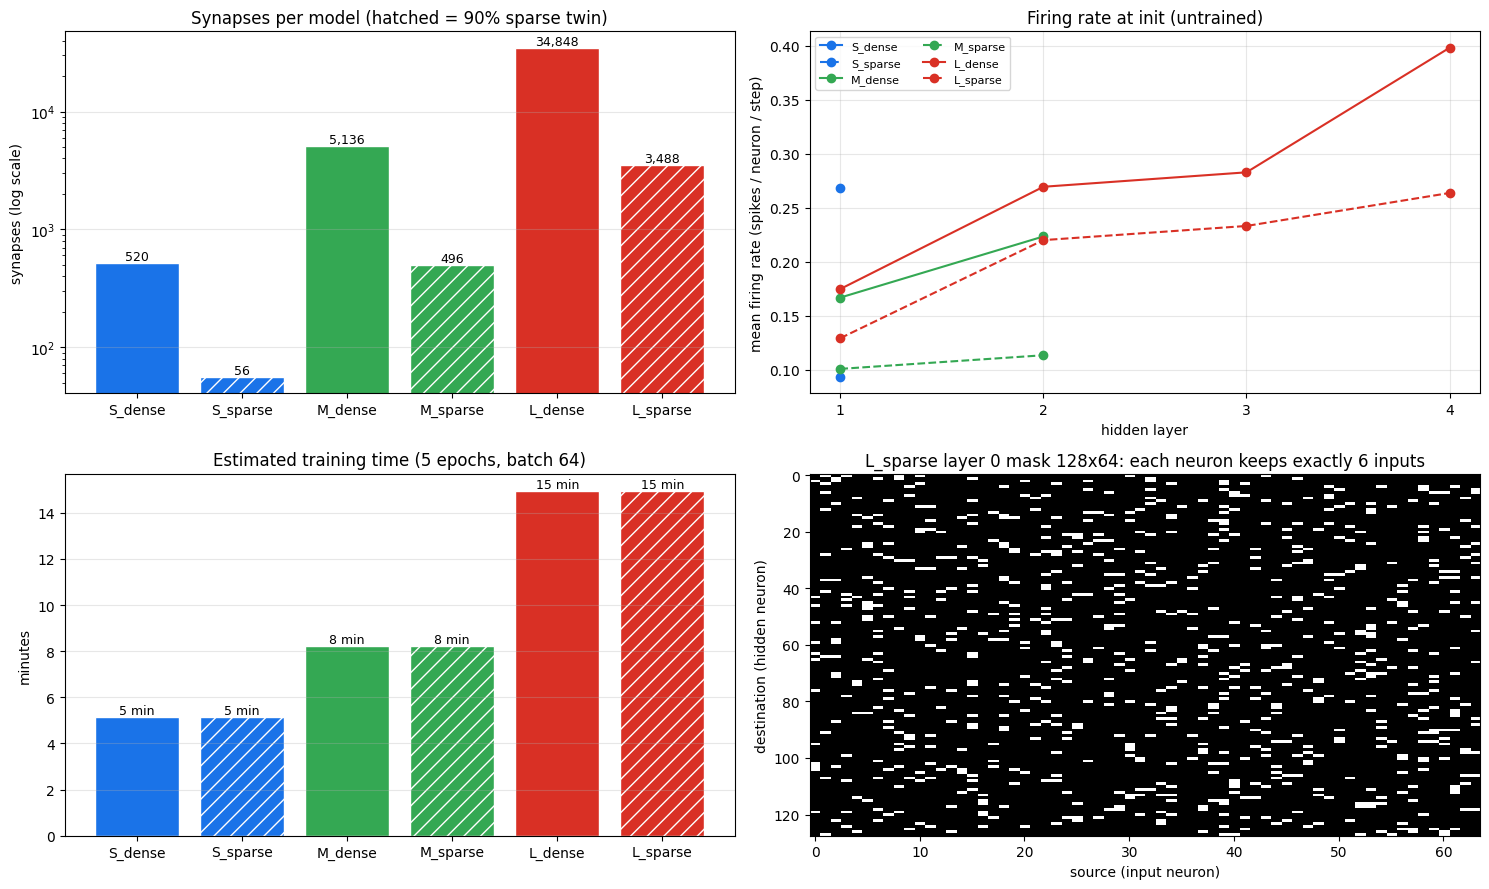


Saved figure: /content/drive/MyDrive/Prototype_7/figures/02_architecture_and_benchmark.png
Cell 3 complete.


In [4]:
# ===================== CELL 3: 4_HG architecture (copied) + 6-model ladder + init check + step-time benchmark =====================

# ---------- Constants (4_HG Cell 2; EPOCHS = 5 as requested) ----------
BETA = 0.9          # membrane leak
THRESH = 1.0        # spike threshold
INIT_GAIN = 2.5     # weight init scale (raise if layers start silent, lower if they saturate)
SURR_K = 10.0       # surrogate gradient sharpness

EPOCHS = 5
BATCH = 64
LR = 2e-3
PATIENCE = 8        # copied from 4_HG (never fires with only 5 epochs)
EVAL_BS = 225       # forward-only batch size (450 val/test windows = 2 batches)

# ---------- Spiking building blocks: COPIED from 4_HG ----------
class SpikeFn(torch.autograd.Function):
    """Heaviside forward, fast-sigmoid surrogate gradient backward."""
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return (x > 0).float()

    @staticmethod
    def backward(ctx, grad_out):
        (x,) = ctx.saved_tensors
        return grad_out / (1.0 + SURR_K * x.abs()) ** 2

spike_fn = SpikeFn.apply

def make_mask(out_f, in_f, sparsity, gen):
    """Fixed fan-in random mask: every neuron keeps exactly k incoming synapses (no dead rows)."""
    if sparsity <= 0:
        return torch.ones(out_f, in_f)
    k = max(1, int(round((1.0 - sparsity) * in_f)))
    scores = torch.rand(out_f, in_f, generator=gen)
    idx = scores.topk(k, dim=1).indices
    mask = torch.zeros(out_f, in_f)
    mask.scatter_(1, idx, 1.0)
    return mask

class MaskedLinear(nn.Module):
    def __init__(self, in_f, out_f, sparsity, gen):
        super().__init__()
        mask = make_mask(out_f, in_f, sparsity, gen)
        k_eff = mask.sum(1).mean().item()
        self.weight = nn.Parameter(torch.randn(out_f, in_f, generator=gen) * (INIT_GAIN / np.sqrt(k_eff)))
        self.bias = nn.Parameter(torch.zeros(out_f))
        self.register_buffer("mask", mask)

    def forward(self, x):
        return F.linear(x, self.weight * self.mask, self.bias)

class SNN(nn.Module):
    def __init__(self, sizes, sparsity, seed=SEED):
        super().__init__()
        gen = torch.Generator().manual_seed(seed)
        self.sizes = sizes
        self.layers = nn.ModuleList(
            [MaskedLinear(sizes[i], sizes[i + 1], sparsity[i], gen) for i in range(len(sizes) - 1)]
        )

    def forward(self, x, return_spikes=False):
        # x: (B, T, 64) float. Returns logits (B,) and optionally per-hidden-layer spikes (B, T, N).
        B, T, _ = x.shape
        n_hidden = len(self.layers) - 1
        mems = [torch.zeros(B, self.sizes[i + 1], device=x.device) for i in range(n_hidden)]
        out_mem = torch.zeros(B, self.sizes[-1], device=x.device)
        out_trace = []
        rec = [[] for _ in range(n_hidden)] if return_spikes else None

        for t in range(T):
            inp = x[:, t]
            for i in range(n_hidden):
                mems[i] = BETA * mems[i] + self.layers[i](inp)
                s = spike_fn(mems[i] - THRESH)
                mems[i] = mems[i] - s.detach() * THRESH   # reset by subtraction
                inp = s
                if return_spikes:
                    rec[i].append(s.detach())

            # readout: non-spiking leaky integrator
            out_mem = BETA * out_mem + self.layers[-1](inp)
            out_trace.append(out_mem)

        logits = torch.stack(out_trace, dim=1).mean(dim=1).squeeze(-1)   # (B,)
        if return_spikes:
            return logits, [torch.stack(r, dim=1) for r in rec]
        return logits

    def synapse_report(self):
        rows = []
        for i, l in enumerate(self.layers):
            rows.append((i, self.sizes[i], self.sizes[i + 1], int(l.mask.sum().item()), l.mask.numel()))
        return rows

# ---------- The 6-model ladder (same ARCHS format as 4_HG; sparsity[i] applies to layer i, readout always dense) ----------
ARCHS = {
    "S_dense":  {"name": "Small dense",   "sizes": [64, 8, 1],                "sparsity": [0.0, 0.0]},
    "S_sparse": {"name": "Small sparse",  "sizes": [64, 8, 1],                "sparsity": [0.9, 0.0]},
    "M_dense":  {"name": "Medium dense",  "sizes": [64, 64, 16, 1],           "sparsity": [0.0, 0.0, 0.0]},
    "M_sparse": {"name": "Medium sparse", "sizes": [64, 64, 16, 1],           "sparsity": [0.9, 0.9, 0.0]},
    "L_dense":  {"name": "Large dense",   "sizes": [64, 128, 128, 64, 32, 1], "sparsity": [0.0, 0.0, 0.0, 0.0, 0.0]},
    "L_sparse": {"name": "Large sparse",  "sizes": [64, 128, 128, 64, 32, 1], "sparsity": [0.9, 0.9, 0.9, 0.9, 0.0]},
}

def build_model(key):
    spec = ARCHS[key]
    torch.manual_seed(SEED)                      # same seeding as 4_HG train_model
    return SNN(spec["sizes"], spec["sparsity"]).to(device)

# ---------- Evaluation helpers (4_HG predict / firing_stats, adapted to uint8 GPU windows) ----------
@torch.no_grad()
def predict(model, x_u8, bs=EVAL_BS):
    model.eval()
    return torch.cat([model(to_bt(x_u8[i:i + bs])) for i in range(0, len(x_u8), bs)])

@torch.no_grad()
def firing_stats(model, x_u8, bs=EVAL_BS):
    """Per hidden layer: mean rate (spikes/neuron/step) and number of silent neurons."""
    model.eval()
    sums, count = None, 0
    for i in range(0, len(x_u8), bs):
        _, spk = model(to_bt(x_u8[i:i + bs]), return_spikes=True)
        batch_sums = [s.sum(dim=(0, 1)) for s in spk]
        sums = batch_sums if sums is None else [a + b for a, b in zip(sums, batch_sums)]
        count += spk[0].shape[0] * spk[0].shape[1]
    stats = []
    for li, s in enumerate(sums):
        rate = (s / count).cpu().numpy()
        stats.append({"layer": li, "neurons": int(len(rate)), "mean_rate": float(rate.mean()),
                      "max_rate": float(rate.max()), "silent": int((rate == 0).sum())})
    return stats

def _sync():
    if device == "cuda":
        torch.cuda.synchronize()

# ---------- 1) Ladder report ----------
print(f"{'key':<10}{'sizes':<28}{'nodes':>6}{'synapses':>10}{'of':>9}{'density':>9}{'cores@32':>10}  orphan sources per layer")
print("-" * 112)
masks_store, syn_count = {}, {}
for key, spec in ARCHS.items():
    m = build_model(key)
    rep = m.synapse_report()
    kept, tot = sum(r[3] for r in rep), sum(r[4] for r in rep)
    nodes = sum(spec["sizes"])
    masks_store[key] = [l.mask.cpu().numpy() for l in m.layers]
    syn_count[key] = kept
    orphans = [int((mk.sum(0) == 0).sum()) for mk in masks_store[key]]     # sources that feed nobody
    print(f"{key:<10}{str(spec['sizes']):<28}{nodes:>6}{kept:>10}{tot:>9}{kept/tot:>9.1%}{math.ceil(nodes/32):>10}  {orphans}")
    del m
print("(cores@32 is only for orientation here; the real value is set in the hypergraph cells)")

# ---------- 2) Health check at init (4_HG prints this before training) ----------
print("\nInitial firing (first 64 val windows): per hidden layer = mean rate | silent neurons")
init_stats, warn = {}, []
for key in ARCHS:
    m = build_model(key)
    st = firing_stats(m, val_x_u8[:64])
    init_stats[key] = st
    line = " | ".join(f"H{s['layer']+1} {s['mean_rate']:.3f} | {s['silent']}/{s['neurons']}" for s in st)
    print(f"  {key:<9} {line}")
    for s in st:
        if s["mean_rate"] < 0.001 or s["silent"] > 0.5 * s["neurons"]:
            warn.append(f"{key} H{s['layer']+1}: (almost) silent")
        if s["mean_rate"] > 0.5:
            warn.append(f"{key} H{s['layer']+1}: saturated")
    del m
print("  " + ("✅ no silent or saturated layers at init" if not warn else "⚠️ " + "; ".join(warn)))
if warn:
    print("     (tell me before training: the knob is INIT_GAIN, copied as 2.5 from 4_HG)")

# ---------- 3) Step-time benchmark: dense S / M / L (a sparse twin runs the same ops, so same cost) ----------
def time_train_step(key, batch=BATCH):
    model = build_model(key)
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)

    # warm-up on a SHORT sequence (T = 64) so CUDA kernels are initialised; costs almost nothing
    xw = to_bt(train_x_u8[:batch, :, :64])
    loss = F.binary_cross_entropy_with_logits(model(xw), train_y[:batch])
    opt.zero_grad(); loss.backward(); opt.step()

    # one real step: full 2048 time steps, batch = BATCH
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    _sync(); t0 = time.time()
    logits = model(to_bt(train_x_u8[:batch]))
    loss = F.binary_cross_entropy_with_logits(logits, train_y[:batch])
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    _sync(); step_s = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float('nan')

    # one eval forward (EVAL_BS windows)
    model.eval()
    with torch.no_grad():
        _sync(); t1 = time.time()
        model(to_bt(val_x_u8[:EVAL_BS]))
        _sync(); eval_s = time.time() - t1

    del model, opt, logits, loss
    if device == "cuda":
        torch.cuda.empty_cache()
    return step_s, eval_s, peak

print("\nBenchmarking one training step per size (full 2048-step windows, batch %d)..." % BATCH)
steps_per_epoch = math.ceil(len(train_x_u8) / BATCH)
val_batches = math.ceil(len(val_x_u8) / EVAL_BS)
final_eval_batches = math.ceil(len(train_x_u8) / EVAL_BS) + val_batches + math.ceil(len(test_x_u8) / EVAL_BS)

bench = {}
for size_key in ["S_dense", "M_dense", "L_dense"]:
    step_s, eval_s, peak = time_train_step(size_key)
    epoch_s = steps_per_epoch * step_s + val_batches * eval_s
    total_min = (EPOCHS * epoch_s + final_eval_batches * eval_s) / 60
    bench[size_key[0]] = dict(step_s=step_s, eval_s=eval_s, peak_gb=peak, epoch_s=epoch_s, total_min=total_min)
    print(f"  {size_key}: step {step_s:6.2f}s | eval batch {eval_s:5.2f}s | peak GPU {peak:4.1f} GB")

print(f"\n{'size':<8}{'step (s)':>10}{'steps/epoch':>13}{'1 epoch (min)':>15}{'5 epochs + final eval (min)':>30}")
for s in ["S", "M", "L"]:
    b = bench[s]
    print(f"{s:<8}{b['step_s']:>10.2f}{steps_per_epoch:>13}{b['epoch_s']/60:>15.1f}{b['total_min']:>30.1f}")
est = {key: bench[key[0]]["total_min"] for key in ARCHS}
total_all = sum(est.values())
print(f"\nEstimated total to train all 6 models: {total_all:.0f} min  (= {total_all/60:.1f} h)")
print("Estimate assumes 5 epochs, batch 64, no early stop; the sparse twin costs the same as its dense twin.")

# ---------- 4) Graphs ----------
size_color = {"S": "#1a73e8", "M": "#34a853", "L": "#d93025"}
keys = list(ARCHS)
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (a) synapses kept
a = ax[0, 0]
bars = a.bar(keys, [syn_count[k] for k in keys],
             color=[size_color[k[0]] for k in keys],
             hatch=['' if 'dense' in k else '//' for k in keys], edgecolor='white')
a.set_yscale('log'); a.set_ylabel('synapses (log scale)')
for b, k in zip(bars, keys):
    a.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{syn_count[k]:,}", ha='center', va='bottom', fontsize=9)
a.set_title('Synapses per model (hatched = 90% sparse twin)'); a.grid(axis='y', alpha=0.3)

# (b) initial firing per hidden layer
a = ax[0, 1]
for k in keys:
    ys = [s['mean_rate'] for s in init_stats[k]]
    a.plot(range(1, len(ys) + 1), ys, marker='o', color=size_color[k[0]],
           ls='-' if 'dense' in k else '--', label=k)
a.set_xlabel('hidden layer'); a.set_ylabel('mean firing rate (spikes / neuron / step)')
a.set_xticks(range(1, 5)); a.set_title('Firing rate at init (untrained)'); a.legend(fontsize=8, ncol=2); a.grid(alpha=0.3)

# (c) estimated training time
a = ax[1, 0]
bars = a.bar(keys, [est[k] for k in keys], color=[size_color[k[0]] for k in keys],
             hatch=['' if 'dense' in k else '//' for k in keys], edgecolor='white')
for b, k in zip(bars, keys):
    a.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{est[k]:.0f} min", ha='center', va='bottom', fontsize=9)
a.set_ylabel('minutes'); a.set_title(f'Estimated training time ({EPOCHS} epochs, batch {BATCH})'); a.grid(axis='y', alpha=0.3)

# (d) one real mask
a = ax[1, 1]
mk = masks_store["L_sparse"][0]
a.imshow(mk, cmap='gray', aspect='auto', interpolation='none')
a.set_title(f"L_sparse layer 0 mask {mk.shape[0]}x{mk.shape[1]}: each neuron keeps exactly {int(mk.sum(1)[0])} inputs")
a.set_xlabel('source (input neuron)'); a.set_ylabel('destination (hidden neuron)')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, '02_architecture_and_benchmark.png')
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"\nSaved figure: {fig_path}")
print("Cell 3 complete.")


=== Model S_dense: Small dense [64, 8, 1] ===
  layer 0: 64->8 synapses 512/512 (100.0% kept)
  layer 1: 8->1 synapses 8/8 (100.0% kept)
  ep  1 train_loss 0.0464 val_loss 0.0367 val_auc 1.0000 (59s)
  ep  2 train_loss 0.0308 val_loss 0.0239 val_auc 1.0000 (118s)
  ep  3 train_loss 0.0251 val_loss 0.0207 val_auc 1.0000 (176s)
  ep  4 train_loss 0.0223 val_loss 0.0220 val_auc 1.0000 (235s)
  ep  5 train_loss 0.0201 val_loss 0.0152 val_auc 1.0000 (294s)
  best epoch 5 | AUC train 0.9885 val 1.0000 test 1.0000 | test sens 1.000 spec 1.000 | dead False | gate PASS | 4.9 min

=== Model S_sparse: Small sparse [64, 8, 1] ===
  layer 0: 64->8 synapses 48/512 (9.4% kept)
  layer 1: 8->1 synapses 8/8 (100.0% kept)
  ep  1 train_loss 0.5822 val_loss 0.1907 val_auc 0.1209 (59s)
  ep  2 train_loss 0.2068 val_loss 0.1069 val_auc 0.1742 (117s)
  ep  3 train_loss 0.1582 val_loss 0.1003 val_auc 0.2324 (176s)
  ep  4 train_loss 0.1440 val_loss 0.0911 val_auc 0.3161 (235s)
  ep  5 train_loss 0.1292 val_

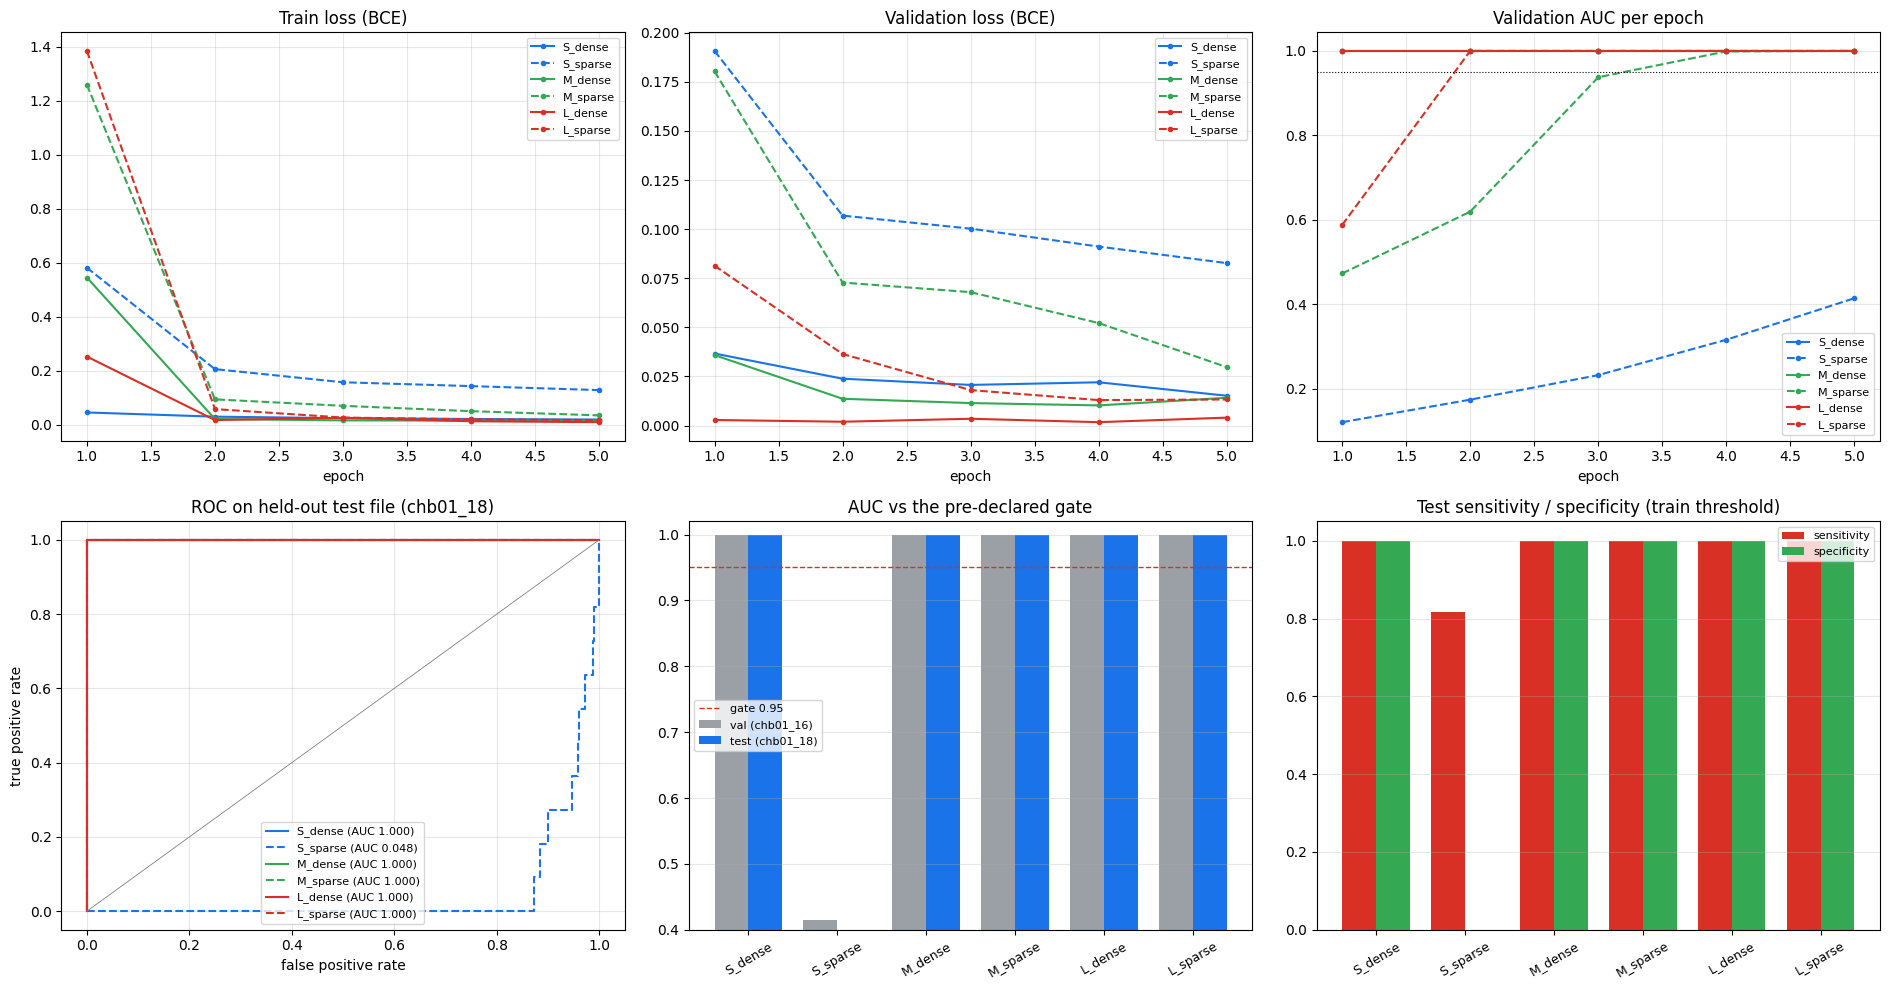


Models saved in: /content/drive/MyDrive/Prototype_7/models
Saved figure: /content/drive/MyDrive/Prototype_7/figures/03_training_results.png
Cell 4 complete.


In [5]:
# ===================== CELL 4: Training (4_HG train_model, 5 epochs) + gate + save to Prototype_7 + graphs =====================
import pandas as pd

# ---------- CONTROL PANEL ----------
TRAIN_KEYS    = list(ARCHS)     # e.g. ["S_dense", "S_sparse"] to train only a few per session
FORCE_RETRAIN = False           # False = skip any model already saved in Prototype_7/models (resume after a disconnect)
GATE_AUC      = 0.95            # pre-declared: valid = no dead output AND val AUC >= GATE_AUC AND test AUC >= GATE_AUC

# ---------- 4_HG evaluate (BCE loss + AUC; accuracy at logit>0 dropped: meaningless at 1-2% seizure windows) ----------
def evaluate(model, x_u8, y):
    logits = predict(model, x_u8)
    loss = F.binary_cross_entropy_with_logits(logits, y).item()
    auc = roc_auc_score(y.cpu().numpy(), logits.cpu().numpy())
    return {"loss": loss, "auc": float(auc)}

# ---------- Final evaluation (Prototype 6 gate logic: threshold chosen by Youden J on TRAIN only) ----------
def split_metrics(l, y, th):
    pred = (l >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"auc": float(roc_auc_score(y, l)),
            "sens": float(tp / (tp + fn)) if (tp + fn) else float('nan'),
            "spec": float(tn / (tn + fp)) if (tn + fp) else float('nan'),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def full_eval(model):
    lt = predict(model, train_x_u8).cpu().numpy()
    lv = predict(model, val_x_u8).cpu().numpy()
    ls = predict(model, test_x_u8).cpu().numpy()
    fpr, tpr, ths = roc_curve(train_labels, lt)
    th = float(ths[np.argmax(tpr - fpr)])
    ev = {"threshold_from_train": th,
          "train": split_metrics(lt, train_labels, th),
          "val":   split_metrics(lv, val_labels, th),
          "test":  split_metrics(ls, test_labels, th),
          "dead_output": bool(lv.std() < 1e-6)}
    return ev, {"train": lt, "val": lv, "test": ls}

def gate_ok(r):
    return (not r["dead_output"]) and r["val"]["auc"] >= GATE_AUC and r["test"]["auc"] >= GATE_AUC

# ---------- Training: copied from 4_HG train_model (data helpers adapted to the uint8 GPU windows) ----------
def train_model(key):
    spec = ARCHS[key]
    model = build_model(key)                 # torch.manual_seed(SEED) + SNN(...), exactly as in 4_HG
    opt = torch.optim.Adam(model.parameters(), lr=LR)

    print(f"\n=== Model {key}: {spec['name']} {spec['sizes']} ===")
    for (i, a, b, nz, tot) in model.synapse_report():
        print(f"  layer {i}: {a}->{b} synapses {nz}/{tot} ({100*nz/tot:.1f}% kept)")

    hist = {"train_loss": [], "val_loss": [], "val_auc": []}
    best = {"auc": -1, "loss": 1e9, "state": None, "epoch": -1}
    bad = 0
    t0 = time.time()

    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(train_x_u8), device=device)
        run_loss, nb = 0.0, 0
        for i in range(0, len(train_x_u8), BATCH):
            idx = perm[i:i + BATCH]
            logits = model(to_bt(train_x_u8[idx]))
            loss = F.binary_cross_entropy_with_logits(logits, train_y[idx])

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

            run_loss += loss.item(); nb += 1

        v = evaluate(model, val_x_u8, val_y)
        hist["train_loss"].append(run_loss / nb); hist["val_loss"].append(v["loss"]); hist["val_auc"].append(v["auc"])
        print(f"  ep {ep+1:2d} train_loss {run_loss/nb:.4f} val_loss {v['loss']:.4f} "
              f"val_auc {v['auc']:.4f} ({time.time()-t0:.0f}s)")

        improved = (v["auc"] > best["auc"] + 1e-4) or (abs(v["auc"] - best["auc"]) <= 1e-4 and v["loss"] < best["loss"])
        if improved:
            best.update(auc=v["auc"], loss=v["loss"], epoch=ep + 1,
                        state={k: t.detach().clone() for k, t in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print("  early stop"); break

    model.load_state_dict(best["state"])
    train_time = time.time() - t0
    ev, sc = full_eval(model)
    res = {"key": key, "name": spec["name"], "sizes": spec["sizes"], "sparsity": spec["sparsity"],
           "best_epoch": best["epoch"], "epochs_run": len(hist["val_auc"]), "train_time_s": train_time,
           "synapses": int(sum(nz for _, _, _, nz, _ in model.synapse_report())),
           "firing_val": firing_stats(model, val_x_u8), **ev}
    print(f"  best epoch {best['epoch']} | AUC train {res['train']['auc']:.4f} val {res['val']['auc']:.4f} "
          f"test {res['test']['auc']:.4f} | test sens {res['test']['sens']:.3f} spec {res['test']['spec']:.3f} | "
          f"dead {res['dead_output']} | gate {'PASS' if gate_ok(res) else 'FAIL'} | {train_time/60:.1f} min")

    # ---------- Save (4_HG checkpoint format + extras) in Prototype_7/models ----------
    torch.save({"state_dict": model.state_dict(), "sizes": spec["sizes"], "sparsity": spec["sparsity"],
                "beta": BETA, "thresh": THRESH, "init_gain": INIT_GAIN, "seed": SEED,
                "key": key, "epochs": EPOCHS, "batch": BATCH, "lr": LR},
               os.path.join(MODEL_DIR, f"model_{key}.pt"))
    with open(os.path.join(MODEL_DIR, f"results_{key}.json"), "w") as f:
        json.dump({"results": res, "history": hist}, f, indent=2)
    np.savez(os.path.join(MODEL_DIR, f"scores_{key}.npz"), **sc)
    del model, opt
    torch.cuda.empty_cache()
    return res, hist, sc

# ---------- Run (skips models already saved) ----------
results, histories, scores = {}, {}, {}
for key in ARCHS:
    ckpt  = os.path.join(MODEL_DIR, f"model_{key}.pt")
    rjson = os.path.join(MODEL_DIR, f"results_{key}.json")
    snpz  = os.path.join(MODEL_DIR, f"scores_{key}.npz")
    done = all(os.path.exists(p) for p in (ckpt, rjson, snpz))
    if key in TRAIN_KEYS and (FORCE_RETRAIN or not done):
        results[key], histories[key], scores[key] = train_model(key)
    elif done:
        d = json.load(open(rjson)); results[key], histories[key] = d["results"], d["history"]
        z = np.load(snpz); scores[key] = {k: z[k] for k in z.files}
        print(f"[{key}] already trained: loaded results from {MODEL_DIR}")
    else:
        print(f"[{key}] skipped (not in TRAIN_KEYS and nothing saved yet)")

keys = [k for k in ARCHS if k in results]

# ---------- Summary table ----------
print("\n" + "=" * 118)
print(f"ACCURACY GATE: valid = no dead output AND val AUC >= {GATE_AUC} AND test AUC >= {GATE_AUC}   (threshold from TRAIN, Youden J)")
print("=" * 118)
print(f"{'model':<10}{'synapses':>9}{'best ep':>8}{'AUC train':>10}{'AUC val':>9}{'AUC test':>10}{'test sens':>10}{'test spec':>10}{'FP/FN (test)':>14}{'min':>6}  gate")
rows = []
for k in keys:
    r = results[k]
    t = r["test"]
    print(f"{k:<10}{r['synapses']:>9}{r['best_epoch']:>8}{r['train']['auc']:>10.4f}{r['val']['auc']:>9.4f}{r['test']['auc']:>10.4f}"
          f"{t['sens']:>10.3f}{t['spec']:>10.3f}{str(t['FP'])+'/'+str(t['FN']):>14}{r['train_time_s']/60:>6.1f}  {'PASS' if gate_ok(r) else 'FAIL'}")
    rows.append({"model": k, "synapses": r["synapses"], "best_epoch": r["best_epoch"],
                 "auc_train": r["train"]["auc"], "auc_val": r["val"]["auc"], "auc_test": r["test"]["auc"],
                 "test_sens": t["sens"], "test_spec": t["spec"], "train_min": r["train_time_s"] / 60,
                 "gate": "PASS" if gate_ok(r) else "FAIL"})
pd.DataFrame(rows).round(4).to_csv(os.path.join(MODEL_DIR, "training_summary.csv"), index=False)

print("\nTrained firing (val): mean rate | silent neurons per hidden layer")
for k in keys:
    print(f"  {k:<9} " + " | ".join(f"H{s['layer']+1} {s['mean_rate']:.3f} | {s['silent']}/{s['neurons']}" for s in results[k]["firing_val"]))

# ---------- Graphs ----------
def style(k):
    return dict(color=size_color[k[0]], ls='-' if 'dense' in k else '--')

fig, ax = plt.subplots(2, 3, figsize=(19, 10))
for k in keys:
    h = histories[k]; ep = np.arange(1, len(h["train_loss"]) + 1)
    ax[0, 0].plot(ep, h["train_loss"], marker='o', ms=3, label=k, **style(k))
    ax[0, 1].plot(ep, h["val_loss"],   marker='o', ms=3, label=k, **style(k))
    ax[0, 2].plot(ep, h["val_auc"],    marker='o', ms=3, label=k, **style(k))
ax[0, 0].set_title('Train loss (BCE)'); ax[0, 1].set_title('Validation loss (BCE)'); ax[0, 2].set_title('Validation AUC per epoch')
ax[0, 2].axhline(GATE_AUC, color='k', lw=0.8, ls=':')
for a in ax[0]:
    a.set_xlabel('epoch'); a.grid(alpha=0.3); a.legend(fontsize=8)

# ROC on the held-out test file
for k in keys:
    fp_, tp_, _ = roc_curve(test_labels, scores[k]["test"])
    ax[1, 0].plot(fp_, tp_, label=f"{k} (AUC {results[k]['test']['auc']:.3f})", **style(k))
ax[1, 0].plot([0, 1], [0, 1], color='gray', lw=0.6)
ax[1, 0].set_title('ROC on held-out test file (chb01_18)'); ax[1, 0].set_xlabel('false positive rate'); ax[1, 0].set_ylabel('true positive rate')
ax[1, 0].legend(fontsize=8); ax[1, 0].grid(alpha=0.3)

# AUC val vs test with the gate line
x = np.arange(len(keys)); w = 0.38
ax[1, 1].bar(x - w/2, [results[k]["val"]["auc"] for k in keys],  w, label='val (chb01_16)',  color='#9aa0a6')
ax[1, 1].bar(x + w/2, [results[k]["test"]["auc"] for k in keys], w, label='test (chb01_18)', color='#1a73e8')
ax[1, 1].axhline(GATE_AUC, color='#d93025', ls='--', lw=1, label=f'gate {GATE_AUC}')
ax[1, 1].set_xticks(x); ax[1, 1].set_xticklabels(keys, rotation=30, fontsize=9)
ax[1, 1].set_ylim(0.4, 1.02); ax[1, 1].set_title('AUC vs the pre-declared gate'); ax[1, 1].legend(fontsize=8); ax[1, 1].grid(axis='y', alpha=0.3)

# Sensitivity / specificity on test (threshold from train)
ax[1, 2].bar(x - w/2, [results[k]["test"]["sens"] for k in keys], w, label='sensitivity', color='#d93025')
ax[1, 2].bar(x + w/2, [results[k]["test"]["spec"] for k in keys], w, label='specificity', color='#34a853')
ax[1, 2].set_xticks(x); ax[1, 2].set_xticklabels(keys, rotation=30, fontsize=9)
ax[1, 2].set_ylim(0, 1.05); ax[1, 2].set_title('Test sensitivity / specificity (train threshold)'); ax[1, 2].legend(fontsize=8); ax[1, 2].grid(axis='y', alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, '03_training_results.png')
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()

print(f"\nModels saved in: {MODEL_DIR}")
print(f"Saved figure: {fig_path}")
print("Cell 4 complete.")

Models in /content/drive/MyDrive/Prototype_7/models
  ✅ S_dense: loaded | gate PASS
  ⏭️  S_sparse: skipped (failed the accuracy gate; set INCLUDE_FAILED_GATE = True to include it)
  ✅ M_dense: loaded | gate PASS
  ✅ M_sparse: loaded | gate PASS
  ✅ L_dense: loaded | gate PASS
  ✅ L_sparse: loaded | gate PASS

Reload check (recomputed val logits vs saved):
  S_dense   max|diff| 0.00e+00 | val AUC 1.0000 | ✅
  M_dense   max|diff| 0.00e+00 | val AUC 1.0000 | ✅
  M_sparse  max|diff| 0.00e+00 | val AUC 1.0000 | ✅
  L_dense   max|diff| 0.00e+00 | val AUC 1.0000 | ✅
  L_sparse  max|diff| 0.00e+00 | val AUC 1.0000 | ✅

=== Measuring firing rates on 'val' windows: (450, 64, 2048) ===
[S_dense] nodes 73 | hyperedges 72 | synapses 520 ✅ | input rate sum 4.000 (expect 4.0) | silent hidden 0/8 | 1s
    layer mean rates: L0 0.0625 | L1 0.2954 | L2 0.0000   (last = readout, non-spiking)
[M_dense] nodes 145 | hyperedges 144 | synapses 5136 ✅ | input rate sum 4.000 (expect 4.0) | silent hidden 0/80 | 

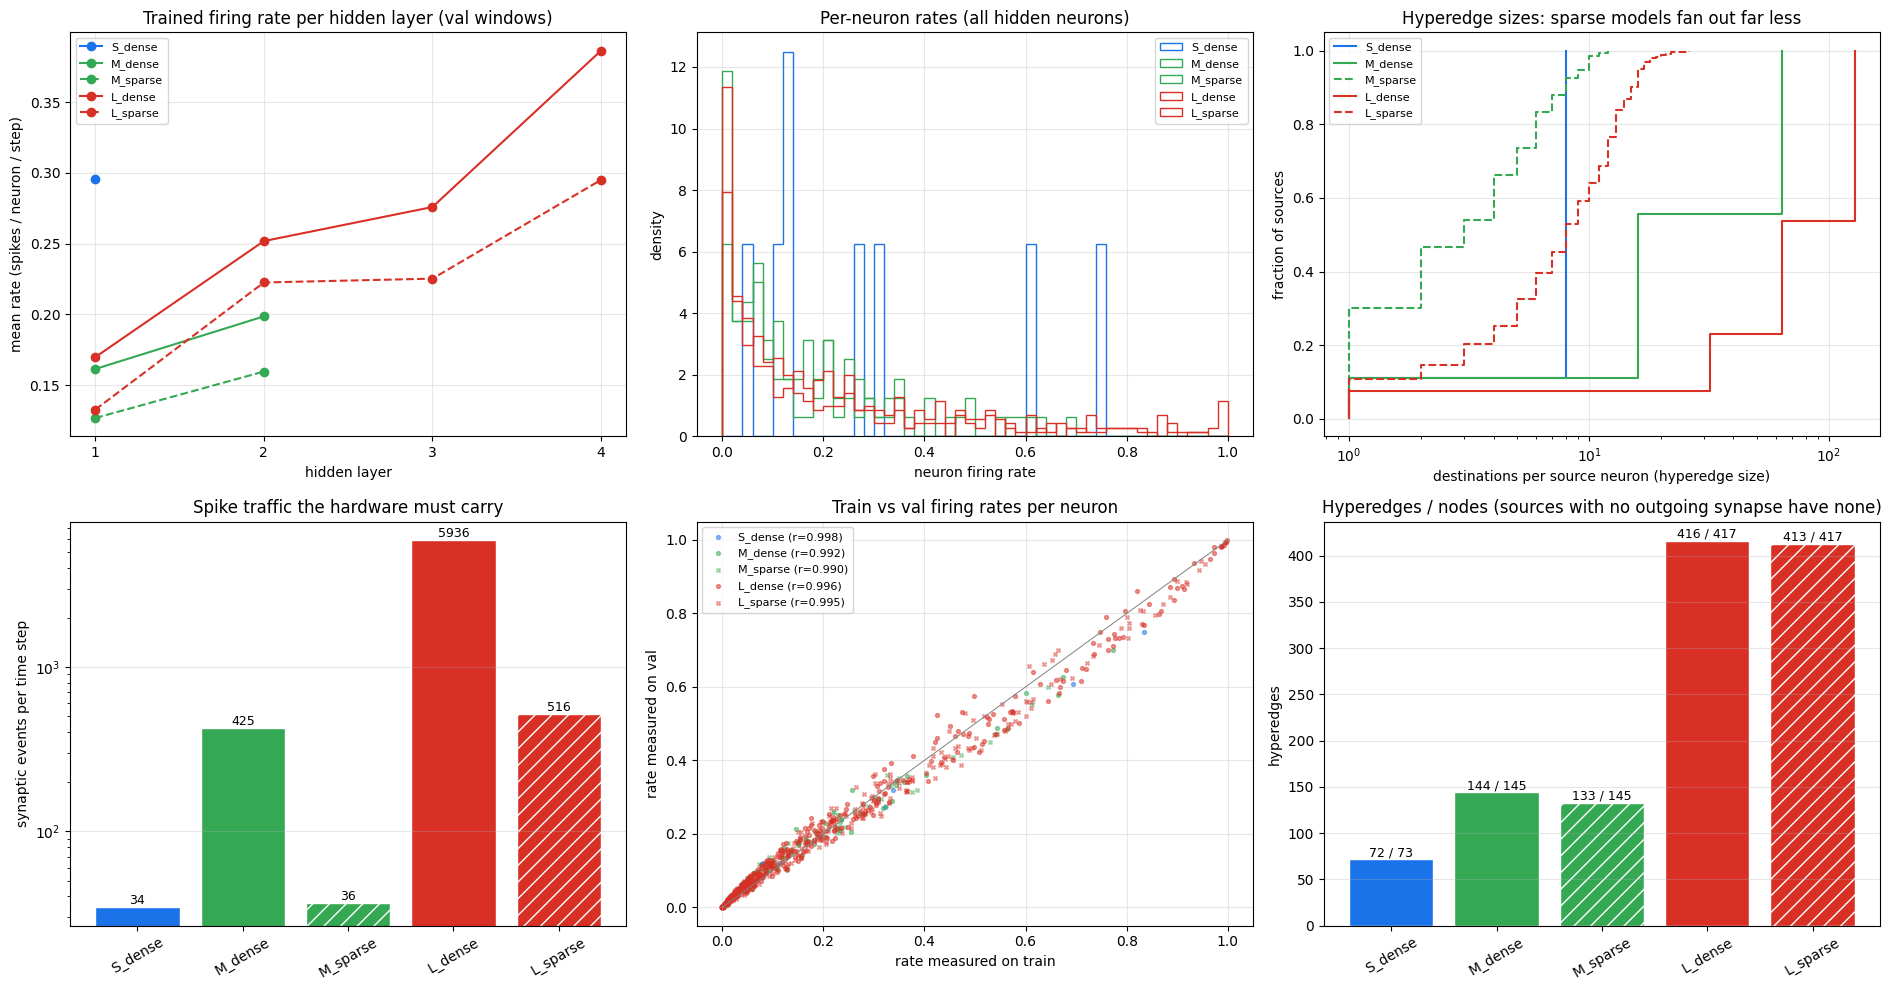


Models in the hypergraph stage: ['S_dense', 'M_dense', 'M_sparse', 'L_dense', 'L_sparse']
Saved figure: /content/drive/MyDrive/Prototype_7/figures/04_hypergraph_extraction.png
Cell 5 complete.


In [7]:
# ===================== CELL 5: Load trained models + hypergraph extraction (adapted to the 4_HG SNN) + graphs =====================
import pickle

# ---------- CONTROL PANEL ----------
HG_MODELS_REQUESTED = list(ARCHS)          # which models to extract
INCLUDE_FAILED_GATE = False                # False = skip models that failed the accuracy gate (S_sparse)
HG_SPLITS_TO_BUILD  = ["val", "train"]     # data used to measure firing rates: any of "train", "val", "test"
HG_BATCH            = 225                  # windows per forward pass (speed only; the rates are identical)
GATE_AUC = globals().get("GATE_AUC", 0.95) # same pre-declared gate as Cell 4

# ---------- Gate status + model loading (4_HG checkpoint format) ----------
def gate_status(key):
    r = json.load(open(os.path.join(MODEL_DIR, f"results_{key}.json")))["results"]
    ok = (not r["dead_output"]) and r["val"]["auc"] >= GATE_AUC and r["test"]["auc"] >= GATE_AUC
    return ok, r

def load_trained(key):
    ck = torch.load(os.path.join(MODEL_DIR, f"model_{key}.pt"), map_location=device)
    m = SNN(ck["sizes"], ck["sparsity"]).to(device)
    m.load_state_dict(ck["state_dict"])          # masks are buffers, so the saved masks overwrite the fresh ones
    m.eval()
    return m

models, res_info = {}, {}
print(f"Models in {MODEL_DIR}")
for key in HG_MODELS_REQUESTED:
    ok, r = gate_status(key)
    res_info[key] = r
    if not ok and not INCLUDE_FAILED_GATE:
        print(f"  ⏭️  {key}: skipped (failed the accuracy gate; set INCLUDE_FAILED_GATE = True to include it)")
        continue
    models[key] = load_trained(key)
    print(f"  ✅ {key}: loaded | gate {'PASS' if ok else 'FAIL'}")

# ---------- Reload check: recomputed val logits must equal the logits saved at training time ----------
print("\nReload check (recomputed val logits vs saved):")
for key, m in models.items():
    saved = np.load(os.path.join(MODEL_DIR, f"scores_{key}.npz"))["val"]
    now = predict(m, val_x_u8).cpu().numpy()
    diff = float(np.abs(saved - now).max())
    print(f"  {key:<9} max|diff| {diff:.2e} | val AUC {roc_auc_score(val_labels, now):.4f} | {'✅' if diff < 1e-3 else '❌ MISMATCH'}")

# ---------- Hypergraph extraction (same contract as 5_HG, adapted to the 4_HG SNN) ----------
@torch.no_grad()
def extract_global_hypergraph(model, x_u8, batch=HG_BATCH):
    """
    Returns:
      nodes       : list of global node ids  [inputs | hidden layers | output]
      h_edges     : {source_node: [destination_nodes]}   one hyperedge per source neuron
      spike_freqs : {node: mean firing rate (spikes / neuron / step)}  measured on real data
      rates       : per-layer rate arrays [input, hidden..., readout]
    """
    model.eval()
    sizes = model.sizes
    offsets = np.cumsum([0] + sizes[:-1]).tolist()
    n_layers = len(sizes)
    n_hidden = n_layers - 2

    # 1) Measure per-neuron firing rates (input rates come straight from the data)
    in_sum = torch.zeros(sizes[0], device=device)
    hid_sums = [torch.zeros(sizes[1 + i], device=device) for i in range(n_hidden)]
    count = 0
    for s in range(0, x_u8.shape[0], batch):
        xb = to_bt(x_u8[s:s + batch])                       # (B, T, 64)
        _, spk = model(xb, return_spikes=True)              # hidden layers only: list of (B, T, N)
        in_sum += xb.sum(dim=(0, 1))
        for i in range(n_hidden):
            hid_sums[i] += spk[i].sum(dim=(0, 1))
        count += xb.shape[0] * xb.shape[1]                  # B * T
    rates = ([(in_sum / count).cpu().numpy()]
             + [(h / count).cpu().numpy() for h in hid_sums]
             + [np.zeros(sizes[-1], dtype=np.float32)])     # readout is a non-spiking integrator: no spikes

    # 2) Input sanity: one-hot encoding -> each channel's 16 levels sum to 1, total = 4
    ch_sums = [rates[0][c * 16:(c + 1) * 16].sum() for c in range(4)]
    if not all(abs(c - 1.0) < 0.05 for c in ch_sums):
        print(f"  ⚠️ input channel sums not ~1.0: {np.round(ch_sums, 3)}")

    # 3) Nodes + spike frequencies
    nodes = list(range(sum(sizes)))
    spike_freqs = {}
    for l in range(n_layers):
        for i in range(sizes[l]):
            spike_freqs[offsets[l] + i] = float(rates[l][i])

    # 4) Hyperedges from the masked wiring: source -> all neurons it connects to
    h_edges = {}
    for l in range(len(model.layers)):
        mask = model.layers[l].mask.cpu()                   # (out, in)
        for src in range(sizes[l]):
            dsts = torch.where(mask[:, src] > 0)[0].tolist()
            if dsts:
                h_edges[offsets[l] + src] = [offsets[l + 1] + d for d in dsts]

    return nodes, h_edges, spike_freqs, rates

# ---------- Run for every requested split, cache to Prototype_7/hypergraph ----------
split_data = {"train": train_x_u8, "val": val_x_u8, "test": test_x_u8}
hg_all = {}
for split in HG_SPLITS_TO_BUILD:
    x_source = split_data[split]
    hypergraphs, layer_rates = {}, {}
    print(f"\n=== Measuring firing rates on '{split}' windows: {tuple(x_source.shape)} ===")
    for key, m in models.items():
        t0 = time.time()
        nodes, h_edges, spike_freqs, rates = extract_global_hypergraph(m, x_source)
        hypergraphs[key] = (nodes, h_edges, spike_freqs)
        layer_rates[key] = rates
        n_syn = sum(len(d) for d in h_edges.values())
        hid = np.concatenate(rates[1:-1])
        syn_ok = (n_syn == res_info[key]["synapses"])
        print(f"[{key}] nodes {len(nodes)} | hyperedges {len(h_edges)} | synapses {n_syn} "
              f"{'✅' if syn_ok else '❌ differs from trained model'} | input rate sum {rates[0].sum():.3f} (expect 4.0) | "
              f"silent hidden {int((hid == 0).sum())}/{hid.size} | {time.time()-t0:.0f}s")
        print("    layer mean rates: " + " | ".join(f"L{l} {r.mean():.4f}" for l, r in enumerate(rates)) + "   (last = readout, non-spiking)")
    cache_path = os.path.join(OUT_DIR, f"hypergraphs_{split}.pkl")
    with open(cache_path, "wb") as f:
        pickle.dump({"hypergraphs": hypergraphs, "layer_rates": layer_rates, "split": split}, f)
    hg_all[split] = (hypergraphs, layer_rates)
    print(f"Saved: {cache_path}")

# ---------- Graphs ----------
plot_split = "val" if "val" in hg_all else HG_SPLITS_TO_BUILD[0]
hgs, lrs = hg_all[plot_split]
mk = list(hgs)
def sty(k): return dict(color=size_color[k[0]], ls='-' if 'dense' in k else '--')

fig, ax = plt.subplots(2, 3, figsize=(19, 10))

# (1) mean firing rate per hidden layer
for k in mk:
    ys = [r.mean() for r in lrs[k][1:-1]]
    ax[0, 0].plot(range(1, len(ys) + 1), ys, marker='o', label=k, **sty(k))
ax[0, 0].set_xticks(range(1, 5)); ax[0, 0].set_xlabel('hidden layer'); ax[0, 0].set_ylabel('mean rate (spikes / neuron / step)')
ax[0, 0].set_title(f'Trained firing rate per hidden layer ({plot_split} windows)'); ax[0, 0].legend(fontsize=8); ax[0, 0].grid(alpha=0.3)

# (2) per-neuron rate distribution
for k in mk:
    hid = np.concatenate(lrs[k][1:-1])
    ax[0, 1].hist(hid, bins=np.linspace(0, 1, 51), histtype='step', density=True, lw=1.6, label=k, **sty(k))
ax[0, 1].set_xlabel('neuron firing rate'); ax[0, 1].set_ylabel('density')
ax[0, 1].set_title('Per-neuron rates (all hidden neurons)'); ax[0, 1].legend(fontsize=8); ax[0, 1].grid(alpha=0.3)

# (3) hyperedge size (fan-out) ECDF
for k in mk:
    sz = np.sort([len(d) for d in hgs[k][1].values()])
    ax[0, 2].plot(sz, np.arange(1, len(sz) + 1) / len(sz), drawstyle='steps-post', label=k, **sty(k))
ax[0, 2].set_xscale('log'); ax[0, 2].set_xlabel('destinations per source neuron (hyperedge size)'); ax[0, 2].set_ylabel('fraction of sources')
ax[0, 2].set_title('Hyperedge sizes: sparse models fan out far less'); ax[0, 2].legend(fontsize=8); ax[0, 2].grid(alpha=0.3)

# (4) synaptic events per time step = sum over sources of (rate x fan-out)
ev = {k: sum(hgs[k][2].get(src, 0) * len(d) for src, d in hgs[k][1].items()) for k in mk}
bars = ax[1, 0].bar(mk, [ev[k] for k in mk], color=[size_color[k[0]] for k in mk],
                    hatch=['' if 'dense' in k else '//' for k in mk], edgecolor='white')
ax[1, 0].set_yscale('log'); ax[1, 0].set_ylabel('synaptic events per time step')
for b, k in zip(bars, mk):
    ax[1, 0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{ev[k]:.0f}", ha='center', va='bottom', fontsize=9)
ax[1, 0].set_title('Spike traffic the hardware must carry'); ax[1, 0].tick_params(axis='x', rotation=30); ax[1, 0].grid(axis='y', alpha=0.3)

# (5) train-measured vs val-measured rates (does the HG_SPLIT choice matter?)
if "train" in hg_all and "val" in hg_all:
    print("\nCorrelation of per-neuron rates, train-measured vs val-measured:")
    for k in mk:
        a = np.concatenate(hg_all["train"][1][k][1:-1]); b = np.concatenate(hg_all["val"][1][k][1:-1])
        r = np.corrcoef(a, b)[0, 1]
        print(f"  {k:<9} r = {r:.4f}")
        ax[1, 1].scatter(a, b, s=8, alpha=0.5, color=size_color[k[0]], marker='o' if 'dense' in k else 'x', label=f"{k} (r={r:.3f})")
    ax[1, 1].plot([0, 1], [0, 1], color='gray', lw=0.7)
    ax[1, 1].set_xlabel('rate measured on train'); ax[1, 1].set_ylabel('rate measured on val')
    ax[1, 1].set_title('Train vs val firing rates per neuron'); ax[1, 1].legend(fontsize=8); ax[1, 1].grid(alpha=0.3)
else:
    ax[1, 1].axis('off'); ax[1, 1].text(0.5, 0.5, 'build both train and val splits\nto see this comparison', ha='center', va='center')

# (6) hyperedge count
bars = ax[1, 2].bar(mk, [len(hgs[k][1]) for k in mk], color=[size_color[k[0]] for k in mk],
                    hatch=['' if 'dense' in k else '//' for k in mk], edgecolor='white')
for b, k in zip(bars, mk):
    ax[1, 2].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{len(hgs[k][1])} / {len(hgs[k][0])}", ha='center', va='bottom', fontsize=9)
ax[1, 2].set_ylabel('hyperedges'); ax[1, 2].set_title('Hyperedges / nodes (sources with no outgoing synapse have none)')
ax[1, 2].tick_params(axis='x', rotation=30); ax[1, 2].grid(axis='y', alpha=0.3)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, '04_hypergraph_extraction.png')
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()

print(f"\nModels in the hypergraph stage: {list(models)}")
print(f"Saved figure: {fig_path}")
print("Cell 5 complete.")